# Nairobi Heat Exposure ABM — Exploratory Notebook

End-to-end walkthrough of the pipeline:
**Phase 1 (data)** → **Phase 2 (simulation)** → **Results**

**Pre-requisites**
```bash
pip install -e ".[dev]"   # from project root
pip install jupyter matplotlib
```
Internet access is required on first run to download the OSM walk network and amenity index.
WorldPop and heat TIFs are optional — synthetic fallbacks are used if the files are absent.

### Data sources

| Input | Source | What it provides | Fallback if absent |
|---|---|---|---|
| Walk network | OpenStreetMap, via `osmnx.graph_from_bbox(network_type="walk")` (Overpass API) | Every walkable way in the study bbox as a `networkx.MultiDiGraph`: nodes = intersections/dead-ends (`x`/`y` = lon/lat, EPSG:4326), edges = street segments (`length` in metres, `travel_time` in seconds, `geometry`) | None &mdash; always a live download on first run; cached to `data/raw/graph.graphml` after that |
| Population | [WorldPop](https://hub.worldpop.org) 100 m gridded population, clipped to the study bbox — 5 rasters: `nairobipop_total.tif` (everyone), `nairobipop_children.tif` (age <=14), `nairobipop_adult.tif` (age >=20), `nairobipop_elderly.tif` (age >=60), `nairobipop_female.tif` (female, any age) | `total` weights where agents "live" (spawn); the other four give each agent's spawn pixel a local age/gender composition, used to draw age group and gender per agent (see `data/demographics.py::draw_age_gender_spatial`) | Uniform synthetic densities for all 5 if `data/raw/nairobipop_total.tif` is absent |
| Matatu network (GTFS) | [DigitalMatatus](http://www.digitalmatatus.com), a crowd-sourced GTFS feed (`GTFS_FEED_2019.zip`, read directly as a zip) | `transit_stop` nodes and `transit` ride edges added to the walk graph, with each edge carrying its trip's frequency bands (this feed is frequency-based, not a literal timetable) | Walk-only graph if no GTFS feed is found at `data/raw/GTFS_FEED_2019.zip` |
| Amenities (POIs) | OpenStreetMap, via `osmnx.features_from_bbox()`, one or more separate tag queries per category merged together (`school`; `food` = `shop=supermarket` + `amenity=marketplace` only, not convenience stores or restaurants; `health`; `other` = `place_of_worship`/`community_centre`/`library`; `work`) | Point/polygon locations for schools, food shops, health facilities, and other destinations, snapped to the nearest graph node | A tag query that errors or times out silently yields an empty list for just that query, not the whole category or a hard error (`data/amenities.py::AMENITY_TAGS`) |
| Heat surface | WRI Thermal Comfort Mapping (TCM) UTCI tiles &mdash; tiled UTM GeoTIFFs, one mosaic per hour-of-day (`UTCI_<year>_<day-of-year>_<HHMM>D.tif`) | Universal Thermal Comfort Index (°C-equivalent) at several times of day, reprojected to EPSG:4326 | Synthetic diurnal surface with a Gaussian urban-heat-island bump if no real tiles are present in `data/raw/heat/` &mdash; **this is the only data source not yet available for Nairobi**; real tiles are still pending in the WRI TCM S3 bucket |

The study area is a single bounding box defined in `config.yaml` (`south=-1.444, west=36.649, north=-1.163, east=37.104` &mdash; greater Nairobi), so every source above is clipped/downloaded to that same extent.

In [1]:
import os
import sys
from pathlib import Path

# Allow imports from project root without pip install
ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Anaconda often sets PROJ_DATA/GDAL_DATA as user-level env vars pointing at its own
# (incompatible) PROJ/GDAL install. That leaks into this .venv kernel and breaks
# rasterio's CRS lookups ("DATABASE.LAYOUT.VERSION.MINOR" errors). Force rasterio's
# own bundled data dirs instead, before any geospatial library touches PROJ/GDAL.
_rasterio_proj_data = ROOT / ".venv" / "Lib" / "site-packages" / "rasterio" / "proj_data"
_rasterio_gdal_data = ROOT / ".venv" / "Lib" / "site-packages" / "rasterio" / "gdal_data"
if _rasterio_proj_data.exists():
    os.environ["PROJ_DATA"] = str(_rasterio_proj_data)
    os.environ.pop("PROJ_LIB", None)
if _rasterio_gdal_data.exists():
    os.environ["GDAL_DATA"] = str(_rasterio_gdal_data)

# overpass-api.de round-robins between backend IPs and one of them is unreachable from
# this network (confirmed via direct socket tests, 2026-09-08) -- osmnx's _config_dns()
# pins every query to whichever IP socket.gethostbyname() happens to return first, so an
# unlucky resolution silently hangs/timeouts every amenity/graph fetch for the whole run.
# Pin to the known-good IP. If this stops working later (server reconfig), re-diagnose with
# socket.create_connection to each IP in socket.getaddrinfo('overpass-api.de', 443).
import socket
_orig_gethostbyname = socket.gethostbyname
def _patched_gethostbyname(hostname):
    if hostname == "overpass-api.de":
        return "162.55.144.139"
    return _orig_gethostbyname(hostname)
socket.gethostbyname = _patched_gethostbyname

import numpy as np
import matplotlib.pyplot as plt
import yaml

with open(ROOT / "config.yaml") as f:
    cfg = yaml.safe_load(f)

b = cfg["bbox"]
BBOX = (b["south"], b["west"], b["north"], b["east"])
SIM  = cfg["simulation"]
PATHS = cfg["paths"]

RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)

print(f"Study bbox : {BBOX}")
print(f"Simulation : {SIM}")

Study bbox : (-1.444, 36.649, -1.163, 37.104)
Simulation : {'start_hour': 6, 'end_hour': 20, 'timestep_seconds': 60, 'default_n_agents': 5000, 'default_seed': 42}


---
## Phase 1 — Data infrastructure
### 1.1  Walk network (OSM via osmnx)

In [2]:
import osmnx as ox
from nairobi_heat_abm.data.graph import build_graph

GRAPH_CACHE = ROOT / PATHS["graph_cache"]
GRAPH_CACHE.parent.mkdir(parents=True, exist_ok=True)
GTFS_PATH = ROOT / PATHS["gtfs_path"]

FORCE_REBUILD_GRAPH = False  # set True to re-download / re-integrate GTFS even if a cache file exists

if GRAPH_CACHE.exists() and not FORCE_REBUILD_GRAPH:
    print(f"Cache hit: loading walk network from {GRAPH_CACHE} …")
else:
    print(f"Cache miss: downloading walk network from OSM (may take ~60 s) …")

gtfs_arg = GTFS_PATH if GTFS_PATH.exists() else None
if gtfs_arg is None:
    print(f"No GTFS feed found at {GTFS_PATH} — building/using a walk-only graph.")

G = build_graph(BBOX, gtfs_path=gtfs_arg, cache_path=GRAPH_CACHE, force_rebuild=FORCE_REBUILD_GRAPH)

n_transit_stops = sum(1 for _, d in G.nodes(data=True) if d.get("node_type") == "transit_stop")
print(f"Graph ready: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges "
      f"({n_transit_stops:,} transit stops)")
if gtfs_arg is not None and n_transit_stops == 0:
    print("WARNING: a GTFS feed is available but the loaded graph has no transit stops — it was "
          "likely cached before GTFS integration existed. Set FORCE_REBUILD_GRAPH=True and rerun "
          "this cell to pick it up.")

Cache hit: loading walk network from C:\Users\tgwon\wri\ride\data\raw\graph.graphml …
Graph ready: 124,298 nodes, 306,655 edges (4,050 transit stops)


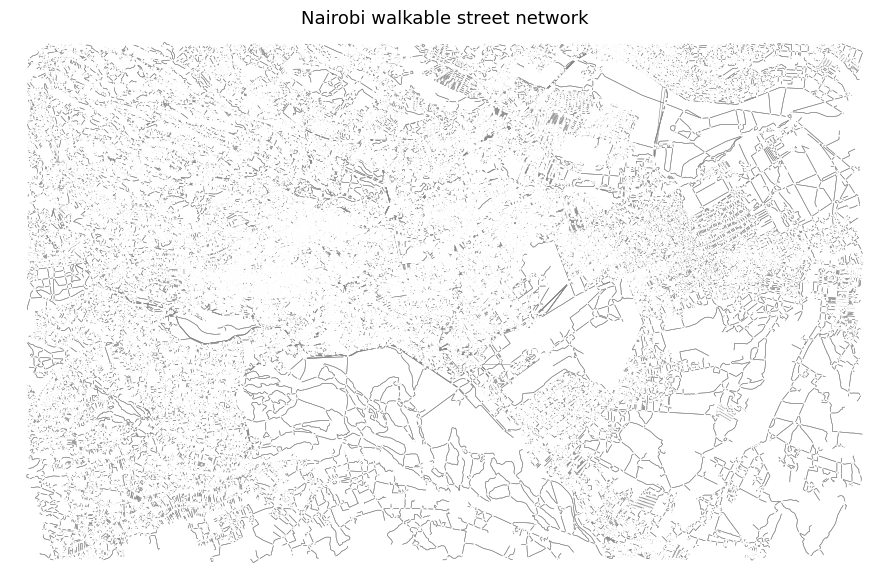

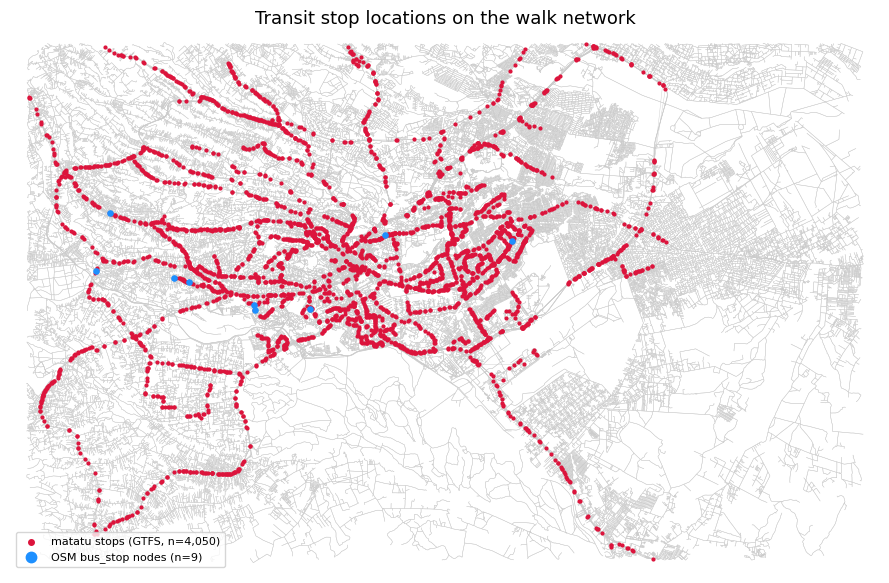

In [3]:
fig, ax = ox.plot_graph(
    G, figsize=(9, 7), show=False, close=False,
    node_size=2, edge_linewidth=0.4, edge_color="#888", bgcolor="white",
)
ax.set_title("Nairobi walkable street network", fontsize=13)
plt.tight_layout()
plt.show()

# Overlay the two kinds of transit-stop point locations:
#  - OSM-tagged bus stops (highway=bus_stop nodes native to the walk-network fetch --
#    very sparse for Nairobi, since OSM bus-stop tagging here is incomplete)
#  - DigitalMatatus GTFS stops (node_type="transit_stop", added by _integrate_gtfs)
bus_stop_xy = [(d["x"], d["y"]) for _, d in G.nodes(data=True) if d.get("highway") == "bus_stop"]
matatu_xy = [(d["x"], d["y"]) for _, d in G.nodes(data=True) if d.get("node_type") == "transit_stop"]

fig, ax = ox.plot_graph(
    G, figsize=(9, 7), show=False, close=False,
    node_size=0, edge_linewidth=0.3, edge_color="#ccc", bgcolor="white",
)
if matatu_xy:
    mx, my = zip(*matatu_xy)
    ax.scatter(mx, my, s=4, c="crimson", label=f"matatu stops (GTFS, n={len(matatu_xy):,})", zorder=3)
if bus_stop_xy:
    bx, by = zip(*bus_stop_xy)
    ax.scatter(bx, by, s=14, c="dodgerblue", label=f"OSM bus_stop nodes (n={len(bus_stop_xy):,})", zorder=4)
ax.set_title("Transit stop locations on the walk network", fontsize=13)
ax.legend(markerscale=2, loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

### 1.1b  Transit network (DigitalMatatus GTFS)

If a GTFS feed was found above, the walk graph now also carries `transit_stop` nodes and `transit` ride edges (`data/graph.py::_integrate_gtfs()`). The DigitalMatatus feed is frequency-based, not a literal timetable — `model/routing.py::route_transit()` looks up each trip's headway band for the agent's actual departure time and models an expected wait of `headway / 2`, rather than matching a departure clock time that doesn't meaningfully exist in this data. This cell exercises it end-to-end on a few sample origin/destination pairs.

In [4]:
from nairobi_heat_abm.model.routing import route_transit, _transit_stops_subgraph, _transit_edges_subgraph

stops_subgraph = _transit_stops_subgraph(G)
transit_subgraph = _transit_edges_subgraph(G)
print(f"Transit stops: {stops_subgraph.number_of_nodes():,}  |  transit ride edges: {transit_subgraph.number_of_edges():,}")

if stops_subgraph.number_of_nodes() > 0:
    sample_rng = np.random.default_rng(7)
    walk_nodes = [n for n, d in G.nodes(data=True) if d.get("node_type") == "intersection"]
    for _ in range(3):
        o, d = sample_rng.choice(walk_nodes, size=2, replace=False)
        try:
            edges = route_transit(
                G, int(o), int(d), departure_tick=90, wait_tolerance_min=15.0, timestep_s=60.0,
                stops_subgraph=stops_subgraph, transit_subgraph=transit_subgraph, start_hour=6,
            )
            used_transit = any(G[u][v][k].get("edge_type") == "transit" for u, v, k, _ in edges)
            wait_ticks = max(w for *_, w in edges)
            label = "transit" if used_transit else "walk only"
            print(f"  {o} -> {d}: {label} route, {len(edges)} edge(s), boarding wait ~{wait_ticks} tick(s)")
        except Exception as exc:
            print(f"  {o} -> {d}: no transit route found ({exc}); would fall back to walking")
else:
    print("No transit stops in this graph — place GTFS_FEED_2019.zip in data/raw/ and rebuild.")

Transit stops: 4,050  |  transit ride edges: 6,753
  12331263129 -> 13651579183: no transit route found (No path between 10000000002674 and 10000000003648.); would fall back to walking
  8585113121 -> 6315531869: no transit route found (No path between 10000000000457 and 10000000000727.); would fall back to walking
  13981955485 -> 8484863115: transit route, 93 edge(s), boarding wait ~2 tick(s)


### 1.2  Population rasters
Place `nairobipop_total.tif`, `nairobipop_children.tif`, `nairobipop_adult.tif`, `nairobipop_elderly.tif`, and `nairobipop_female.tif` in `data/raw/` (100 m WorldPop grids for Kenya, one per demographic group).  
A uniform synthetic fallback is generated for all 5 automatically if `nairobipop_total.tif` is absent.

In [5]:
import rasterio
import rasterio.transform
from nairobi_heat_abm.data.population import load_population_rasters, sample_spawn_nodes

WP_PATHS = {k: ROOT / p for k, p in PATHS["worldpop_tifs"].items()}
WP_PATH = WP_PATHS["total"]  # kept for the cells below that only need the total surface

if all(p.exists() for p in WP_PATHS.values()):
    print(f"Cache hit: loading WorldPop rasters (total/children/adult/elderly/female) from {WP_PATH.parent} …")
    rasters, pop_transform = load_population_rasters(WP_PATHS, BBOX)
else:
    print(f"Cache miss: WorldPop TIFs not found at {WP_PATH.parent} — generating synthetic densities …")
    south, west, north, east = BBOX
    rows, cols = 60, 60
    pop_transform = rasterio.transform.from_bounds(west, south, east, north, cols, rows)
    # Mild density gradient: denser toward the city centre
    yy = np.linspace(0, 1, rows)[:, None]
    xx = np.linspace(0, 1, cols)[None, :]
    total = (1.0 + 2.0 * np.exp(-((xx - 0.45)**2 + (yy - 0.55)**2) / 0.05)).astype(np.float32)

    # No real per-group data yet: synthesize each group as a flat share of `total`,
    # matching DemographicParams' default city-wide shares (child 0.35, adult 20+ =
    # 0.35+0.10 = 0.45, elderly 0.10, female 0.51) — NOT spatially varying, just enough
    # to exercise the pipeline until real per-group WorldPop rasters are supplied.
    rasters = {
        "total": total,
        "children": total * 0.35,
        "adult": total * 0.45,
        "elderly": total * 0.10,
        "female": total * 0.51,
    }
    WP_PATH.parent.mkdir(parents=True, exist_ok=True)
    for key, array in rasters.items():
        with rasterio.open(
            WP_PATHS[key], "w", driver="GTiff",
            height=rows, width=cols, count=1,
            dtype=np.float32, crs="EPSG:4326", transform=pop_transform,
        ) as dst:
            dst.write(array[np.newaxis, :, :])
    print(f"Saved synthetic WorldPop rasters to {WP_PATH.parent} (will be reused on next run)")

density = rasters["total"]
print(f"Density array: shape={density.shape}, range=[{np.nanmin(density):.1f}, {np.nanmax(density):.1f}]")

# Sanity check: if every group raster is identical to "total", per-pixel age/gender
# ratios are degenerate (e.g. 100% one age group everywhere) — flag it rather than
# silently producing a skewed population downstream.
_group_keys = [k for k in rasters if k != "total"]
if all(np.allclose(rasters[k], density, equal_nan=True) for k in _group_keys):
    print("WARNING: children/adult/elderly/female rasters are identical to total — "
          "age/gender draws below will be degenerate until real per-group data is supplied.")

Cache hit: loading WorldPop rasters (total/children/adult/elderly/female) from C:\Users\tgwon\wri\ride\data\raw …
Density array: shape=(313, 506), range=[0.0, 2398.3]


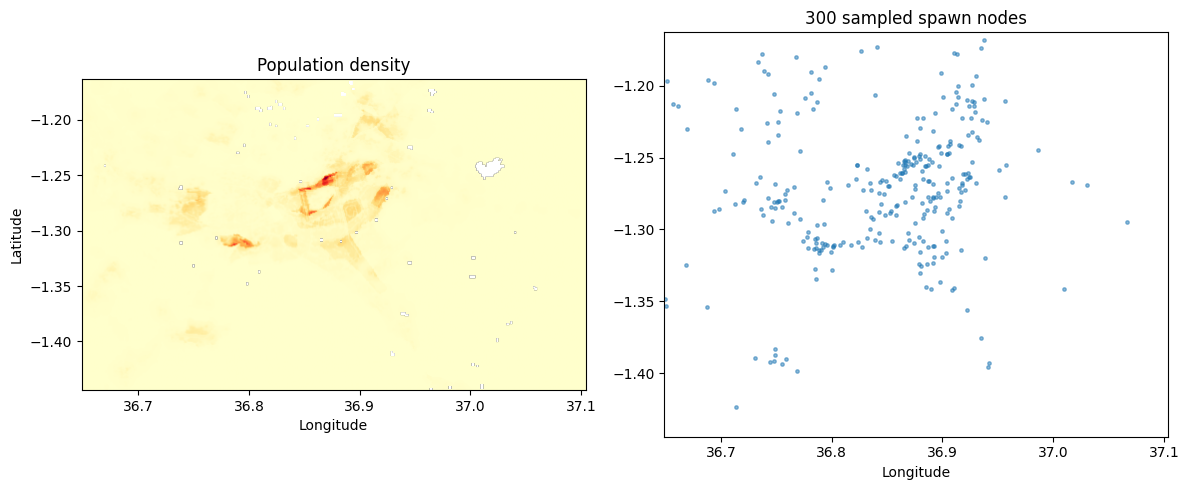

In [6]:
rng = np.random.default_rng(42)
spawn_nodes, spawn_rows, spawn_cols = sample_spawn_nodes(density, pop_transform, G, n_agents=300, rng=rng)
spawn_xs = [G.nodes[n]["x"] for n in spawn_nodes]
spawn_ys = [G.nodes[n]["y"] for n in spawn_nodes]

south, west, north, east = BBOX
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    density, extent=[west, east, south, north],
    origin="upper", cmap="YlOrRd",
)
axes[0].set_title("Population density")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")

axes[1].scatter(spawn_xs, spawn_ys, s=6, alpha=0.5, c="tab:blue")
axes[1].set_xlim(west, east); axes[1].set_ylim(south, north)
axes[1].set_title("300 sampled spawn nodes")
axes[1].set_xlabel("Longitude")

plt.tight_layout()
plt.show()

### 1.3  Heat surface
Place a multi-band GeoTIFF (one band per simulated hour) in `data/raw/heat/`, or a directory of single-band TIFs.  
A synthetic diurnal surface with an urban heat-island gradient is used automatically if no files are present.

In [7]:
from nairobi_heat_abm.data.heat import load_heat_surface, HeatSurface

HEAT_DIR  = ROOT / PATHS["heat_dir"]
HEAT_TIFS = list(HEAT_DIR.glob("*.tif")) + list(HEAT_DIR.glob("*.tiff")) if HEAT_DIR.exists() else []

if HEAT_TIFS:
    surface = load_heat_surface(HEAT_DIR)
    print(f"Loaded heat surface from {HEAT_DIR}: shape={surface.array.shape}, hours={surface.hours}")
else:
    print("No heat TIFs found — building synthetic diurnal surface …")
    south, west, north, east = BBOX
    rows, cols = 60, 60
    htransform = rasterio.transform.from_bounds(west, south, east, north, cols, rows)
    hours = [6, 9, 12, 15, 18]
    base_temps = [26.0, 30.0, 35.0, 33.0, 29.0]  # °C at each hour

    # Urban heat-island: ~4 °C hotter in the centre
    yy = np.linspace(0, 1, rows)[:, None]
    xx = np.linspace(0, 1, cols)[None, :]
    uhi = 4.0 * np.exp(-((xx - 0.45)**2 + (yy - 0.55)**2) / 0.08)

    rng_h = np.random.default_rng(0)
    bands = [
        (t + uhi + rng_h.normal(0, 0.3, (rows, cols))).astype(np.float32)
        for t in base_temps
    ]
    surface = HeatSurface(
        array=np.stack(bands),
        transform=htransform,
        hours=hours,
        crs="EPSG:4326",
        name="synthetic",
    )
    print(f"Synthetic surface: shape={surface.array.shape}, hours={surface.hours}")

No heat TIFs found — building synthetic diurnal surface …
Synthetic surface: shape=(5, 60, 60), hours=[6, 9, 12, 15, 18]


C:\Users\tgwon\AppData\Local\Temp\ipykernel_27936\3777490317.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


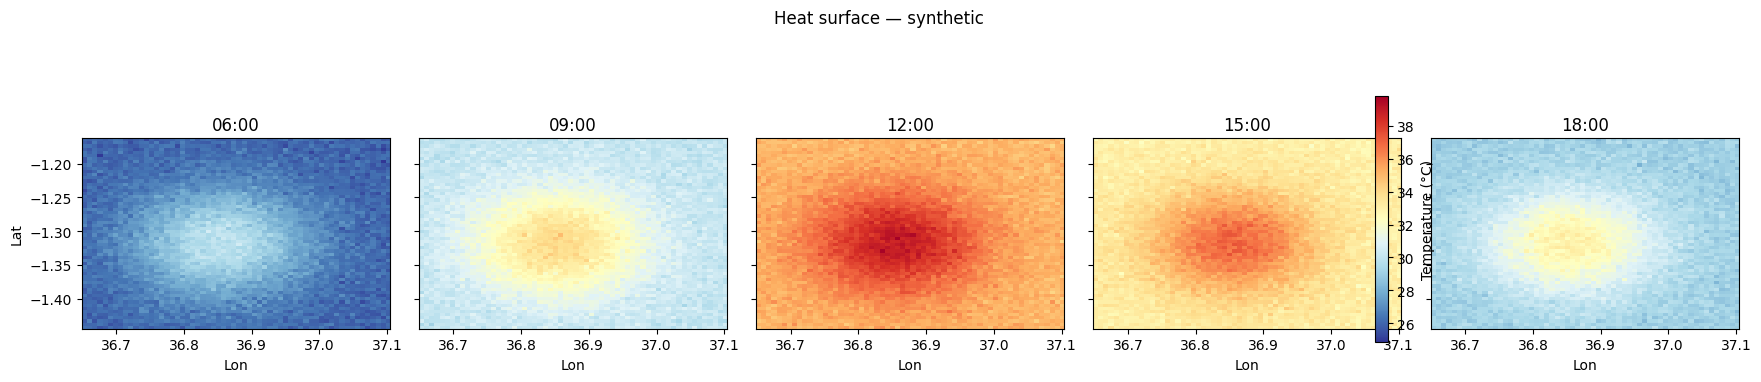

In [8]:
# Visualise temperature at each simulated hour
n_h = len(surface.hours)
fig, axes = plt.subplots(1, n_h, figsize=(3.5 * n_h, 4), sharey=True)
if n_h == 1:
    axes = [axes]

vmin, vmax = surface.array.min(), surface.array.max()
south, west, north, east = BBOX

for ax, band, hour in zip(axes, surface.array, surface.hours):
    im = ax.imshow(
        band, extent=[west, east, south, north],
        origin="upper", cmap="RdYlBu_r", vmin=vmin, vmax=vmax,
    )
    ax.set_title(f"{hour:02d}:00")
    ax.set_xlabel("Lon")

axes[0].set_ylabel("Lat")
fig.colorbar(im, ax=axes, label="Temperature (°C)", shrink=0.8)
fig.suptitle(f"Heat surface — {surface.name}", y=1.02)
plt.tight_layout()
plt.show()

### 1.4  Amenity index (OSM POIs)
Fetches schools, food shops (supermarkets and markets — not convenience stores or restaurants), health facilities, and other POIs and snaps them to the nearest walkable node. Each category is fetched as one or more separate tag queries and merged, so one query failing doesn't silently empty out the whole category (`data/amenities.py::AMENITY_TAGS`).
Result is cached to `data/raw/amenities.json`.

In [9]:
from nairobi_heat_abm.data.amenities import build_amenity_index

AMENITY_CACHE = ROOT / PATHS["amenity_cache"]
FORCE_REBUILD_AMENITIES = False  # set True to re-fetch even if a cache file exists

if AMENITY_CACHE.exists() and not FORCE_REBUILD_AMENITIES:
    print(f"Cache hit: loading amenity index from {AMENITY_CACHE} …")
else:
    print(f"Cache miss: fetching amenity index from OSM …")

amenities = build_amenity_index(BBOX, G, cache_path=AMENITY_CACHE, force_rebuild=FORCE_REBUILD_AMENITIES)

print("\nAmenity counts:")
for cat, nodes in amenities.items():
    print(f"  {cat:8s}: {len(nodes):4d} locations")

Cache hit: loading amenity index from C:\Users\tgwon\wri\ride\data\raw\amenities.json …

Amenity counts:
  school  : 1947 locations
  food    :  430 locations
  health  :  916 locations
  other   : 1389 locations
  work    : 6115 locations


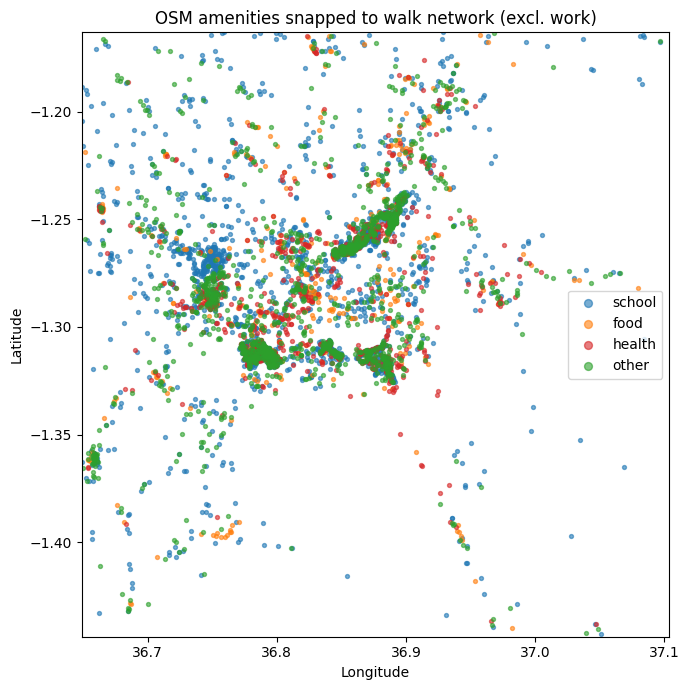

In [10]:
# Spot-check: plot each amenity category on a scatter map
# "work" is excluded here: it's a large merged pool (offices/commercial land plus the
# school/food/health overlap from _add_work_overlap()) that visually obscures the other
# categories on this map, not a data-quality issue.
colours = {"school": "tab:blue", "food": "tab:orange", "health": "tab:red", "other": "tab:green"}
south, west, north, east = BBOX

fig, ax = plt.subplots(figsize=(7, 7))
for cat, node_ids in amenities.items():
    if cat == "work" or not node_ids:
        continue
    xs = [G.nodes[n]["x"] for n in node_ids if G.has_node(n)]
    ys = [G.nodes[n]["y"] for n in node_ids if G.has_node(n)]
    ax.scatter(xs, ys, s=8, alpha=0.6, c=colours[cat], label=cat)

ax.set_xlim(west, east); ax.set_ylim(south, north)
ax.set_title("OSM amenities snapped to walk network (excl. work)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

### How the pipeline represents the world

Everything downstream of Phase 1 loading is built on three plain data structures:

**The walk network** (`networkx.MultiDiGraph`, from `data/graph.py`)
- Nodes: `x`/`y` (lon/lat, EPSG:4326), `node_type` (`"intersection"`, or `"amenity"` once `build_amenity_index()` tags POI nodes).
- Edges: `length` (metres), `travel_time` (seconds, from OSM speed limits), `weight` (routing cost &mdash; currently equal to `travel_time`), `geometry`, and `edge_type` (only set for transit edges once GTFS is integrated &mdash; every current edge is implicitly a walk edge).
- Read-only after `build_graph()` returns it &mdash; nothing in the model layer mutates the graph at runtime.

**Agents** (`AgentPool`, `model/agent.py`) &mdash; columnar NumPy arrays, one row-index per agent, never per-agent Python objects:

| Field | dtype | Meaning |
|---|---|---|
| `edge_u`, `edge_v`, `edge_key` | int | The `(u, v, key)` MultiDiGraph edge the agent is currently on |
| `progress` | float32 | 0.0 (at `u`) &rarr; 1.0 (at `v`) along the current edge |
| `mode` | uint8 | 0 = walk, 1 = wait, 2 = transit |
| `trip_purpose` | uint8 | 0 = work, 1 = school, 2 = market, 3 = other |
| `active` | bool | `False` once the agent's trip is complete (or no route was found) |
| `heat_exposure_degC_min` | float32 | Running total of °C &times; minutes accumulated so far |
| `route_edges` / `route_index` | list / int32 | Per-agent list of `(u, v, key)` tuples from `assign_routes()`, and the agent's current position in that list |

**Heat surface** (`HeatSurface`, `data/heat.py`) &mdash; a `(n_hours, rows, cols)` array plus an affine `transform` and a list of `hours` (one band per simulated hour-of-day). `sample_temperature()` bilinearly interpolates this grid at an agent's interpolated lon/lat for the nearest available hour.

---
## Phase 2 — ABM core
### 2.1  Travel behaviour parameters

In [11]:
from nairobi_heat_abm.model.agent import TravelBehaviorParams

behavior = TravelBehaviorParams()  # walk_only_share defaults to 0.55 -- transit is now real, see §1.1b

print("TravelBehaviorParams (defaults — adjust interactively in §2.1c below)")
print(f"  trip_rate        : {behavior.trip_rate_mean:.1f} ± {behavior.trip_rate_std:.1f} (dist={behavior.trip_rate_distribution})")
print(f"  departure_profile: {behavior.departure_profile}")
print(f"  peak 1           : {behavior.peak1_hour}h  weight={behavior.peak1_weight:.0%}")
print(f"  peak 2           : {behavior.peak2_hour}h  weight={behavior.peak2_weight:.0%}")
print(f"  walk_only_share  : {behavior.walk_only_share:.0%}")
print(f"  purpose_weights  : {behavior.purpose_weights}")
print(f"  travel_probability: {behavior.travel_probability}")

TravelBehaviorParams (defaults — adjust interactively in §2.1c below)
  trip_rate        : 3.2 ± 1.1 (dist=normal)
  departure_profile: bimodal
  peak 1           : 7.5h  weight=45%
  peak 2           : 17.0h  weight=35%
  walk_only_share  : 55%
  purpose_weights  : {'work': 0.4, 'school': 0.2, 'market': 0.25, 'other': 0.15}
  travel_probability: {'work': 1.0, 'school': 1.0, 'market': 1.0, 'other': 1.0}


### 2.1b  Demographics (age/gender/SES)

Agents can optionally carry an age group, gender, and socioeconomic/informality status (`DemographicParams`, `model/agent.py`). Age and gender are drawn **spatially** here — from each agent's local demographic composition at its own spawn pixel, using the WorldPop group rasters loaded in §1.2 above — rather than from flat city-wide shares (`data/demographics.py::draw_age_gender_spatial`).

SES is still derived from an informal-settlement boundary file (`informal_settlement_path`), which stays `None` until real Nairobi boundary data is supplied — every agent is `SES_FORMAL` until then. Behavioural modifiers per age/gender value (`age_modifiers`/`gender_modifiers`) are set interactively in §2.1c below, rather than hardcoded here — see `docs/methodology/travel-behaviour.md` for how they combine with the base `TravelBehaviorParams`.

In [12]:
from nairobi_heat_abm.model.agent import DemographicParams

demographics = DemographicParams(
    population_raster_paths=WP_PATHS,   # spatial age/gender draw, see §1.2 above
    informal_settlement_path=None,      # no real Nairobi boundary data yet -> everyone SES_FORMAL
)

print("DemographicParams")
print(f"  population_raster_paths: {list(demographics.population_raster_paths.keys())}")
print(f"  informal_settlement_path: {demographics.informal_settlement_path}")

DemographicParams
  population_raster_paths: ['total', 'children', 'adult', 'elderly', 'female']
  informal_settlement_path: None


### 2.1c  Interactive movement-behavior controls

Sliders below write directly into the `behavior` and `demographics` objects created above — no separate "apply" step. **Base behavior** sets population-wide `TravelBehaviorParams`; the departure-time preview redraws live as you adjust it. The remaining tabs set an age- or gender-specific `ParamModifier` (`model/agent.py`) that multiplicatively adjusts every field in **Base behavior** for agents with that attribute — age and gender combine independently (a youth-female agent gets `base × age_mult × gender_mult`), not as a full cross-tab of every age/gender combination (see `docs/methodology/travel-behaviour.md`).

`travel_probability` (Base behavior tab) and its per-group `*_mult` (other tabs) are new: each agent draws exactly one destination for one purpose (work/school/market/other), and this is the probability that trip actually happens, conditioned on which purpose was drawn — not an overall "stays home all day" switch. An agent that fails the draw stays inactive for the whole run (zero trips, zero heat exposure).

Changing a slider does **not** re-run the simulation — §2.2 below still needs to be re-executed manually to pick up new values (a full run over `N_AGENTS` agents is too expensive to fire on every drag). Bounds for base fields covered by `rdm/sampling.py::STANDARD_RANGES` reuse those ranges, so exploration here stays consistent with the RDM sweep's parameter space.

Tabs(dynamic=True)
    [0] Column
        [0] Param(BaseBehaviorForm, show_name=False, widgets={'trip_rate_mean': <class ...})
        [1] Matplotlib(Figure, tight=True)
    [1] Param(ModifierForm, show_name=False, widgets={'trip_rate_mean_mult': <c...})
    [2] Param(ModifierForm, show_name=False, widgets={'trip_rate_mean_mult': <c...})
    [3] Param(ModifierForm, show_name=False, widgets={'trip_rate_mean_mult': <c...})
    [4] Param(ModifierForm, show_name=False, widgets={'trip_rate_mean_mult': <c...})
    [5] Param(ModifierForm, show_name=False, widgets={'trip_rate_mean_mult': <c...})
    [6] Param(ModifierForm, show_name=False, widgets={'trip_rate_mean_mult': <c...})
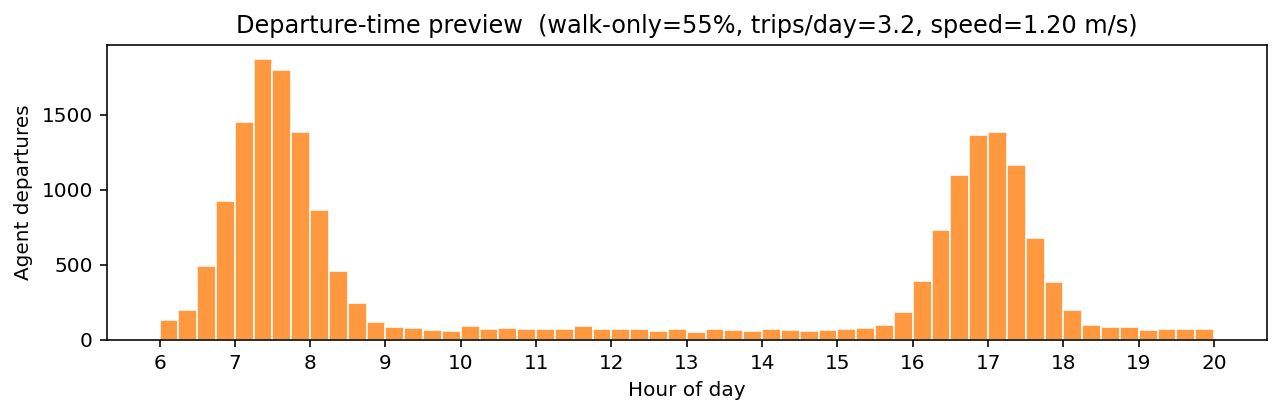

In [13]:
import panel as pn
import param
from IPython.display import display

from nairobi_heat_abm.model.agent import (
    ParamModifier, AGE_CHILD, AGE_YOUTH, AGE_ADULT, AGE_ELDERLY, GENDER_MALE, GENDER_FEMALE,
)
from nairobi_heat_abm.rdm.sampling import STANDARD_RANGES

pn.extension()

_RANGE_BOUNDS = {r.name: (r.min_val, r.max_val) for r in STANDARD_RANGES}


def _bounds(field_name: str, fallback: tuple[float, float]) -> tuple[float, float]:
    return _RANGE_BOUNDS.get(field_name, fallback)


_MULT_BOUNDS = (0.0, 3.0)  # 0 = this group never does it, 1 = no change, up to 3x


class BaseBehaviorForm(param.Parameterized):
    """Population-wide TravelBehaviorParams sliders. Mutates the notebook's `behavior`
    object in place and redraws the departure-time preview on every change."""

    trip_rate_mean = param.Number(default=behavior.trip_rate_mean, bounds=_bounds("trip_rate_mean", (0.5, 8.0)), step=0.1)
    trip_rate_std = param.Number(default=behavior.trip_rate_std, bounds=_bounds("trip_rate_std", (0.1, 3.0)), step=0.1)
    peak1_hour = param.Number(default=behavior.peak1_hour, bounds=_bounds("peak1_hour", (SIM["start_hour"], SIM["end_hour"])), step=0.25)
    peak1_weight = param.Number(default=behavior.peak1_weight, bounds=(0.0, 1.0), step=0.01)
    peak2_hour = param.Number(default=behavior.peak2_hour, bounds=_bounds("peak2_hour", (SIM["start_hour"], SIM["end_hour"])), step=0.25)
    peak2_weight = param.Number(default=behavior.peak2_weight, bounds=(0.0, 1.0), step=0.01)
    walk_only_share = param.Number(default=behavior.walk_only_share, bounds=_bounds("walk_only_share", (0.0, 1.0)), step=0.01)
    walk_speed_mean_mps = param.Number(default=behavior.walk_speed_mean_mps, bounds=_bounds("walk_speed_mean_mps", (0.3, 3.0)), step=0.05)
    walk_speed_std_mps = param.Number(default=behavior.walk_speed_std_mps, bounds=(0.0, 0.5), step=0.01)
    transit_wait_tolerance_min = param.Number(default=behavior.transit_wait_tolerance_min, bounds=_bounds("transit_wait_tolerance_min", (1.0, 60.0)), step=1.0)
    transit_wait_tolerance_std = param.Number(default=behavior.transit_wait_tolerance_std, bounds=(0.0, 15.0), step=0.5)

    purpose_work = param.Number(default=behavior.purpose_weights["work"], bounds=(0.0, 1.0), step=0.01, label="purpose: work")
    purpose_school = param.Number(default=behavior.purpose_weights["school"], bounds=(0.0, 1.0), step=0.01, label="purpose: school")
    purpose_market = param.Number(default=behavior.purpose_weights["market"], bounds=(0.0, 1.0), step=0.01, label="purpose: market")
    purpose_other = param.Number(default=behavior.purpose_weights["other"], bounds=(0.0, 1.0), step=0.01, label="purpose: other")

    travel_prob_work = param.Number(default=behavior.travel_probability["work"], bounds=(0.0, 1.0), step=0.01, label="travel prob: work")
    travel_prob_school = param.Number(default=behavior.travel_probability["school"], bounds=(0.0, 1.0), step=0.01, label="travel prob: school")
    travel_prob_market = param.Number(default=behavior.travel_probability["market"], bounds=(0.0, 1.0), step=0.01, label="travel prob: market")
    travel_prob_other = param.Number(default=behavior.travel_probability["other"], bounds=(0.0, 1.0), step=0.01, label="travel prob: other")

    def __init__(self, **params):
        super().__init__(**params)
        self.preview_pane = pn.pane.Matplotlib(tight=True)
        self._sync()

    @param.depends(
        "trip_rate_mean", "trip_rate_std", "peak1_hour", "peak1_weight", "peak2_hour", "peak2_weight",
        "walk_only_share", "walk_speed_mean_mps", "walk_speed_std_mps",
        "transit_wait_tolerance_min", "transit_wait_tolerance_std",
        "purpose_work", "purpose_school", "purpose_market", "purpose_other",
        "travel_prob_work", "travel_prob_school", "travel_prob_market", "travel_prob_other",
        watch=True,
    )
    def _sync(self) -> None:
        behavior.trip_rate_mean = self.trip_rate_mean
        behavior.trip_rate_std = self.trip_rate_std
        behavior.peak1_hour = self.peak1_hour
        behavior.peak1_weight = self.peak1_weight
        behavior.peak2_hour = self.peak2_hour
        behavior.peak2_weight = self.peak2_weight
        behavior.walk_only_share = self.walk_only_share
        behavior.walk_speed_mean_mps = self.walk_speed_mean_mps
        behavior.walk_speed_std_mps = self.walk_speed_std_mps
        behavior.transit_wait_tolerance_min = self.transit_wait_tolerance_min
        behavior.transit_wait_tolerance_std = self.transit_wait_tolerance_std

        raw_purpose = {
            "work": self.purpose_work, "school": self.purpose_school,
            "market": self.purpose_market, "other": self.purpose_other,
        }
        total = sum(raw_purpose.values()) or 1.0
        behavior.purpose_weights = {k: v / total for k, v in raw_purpose.items()}

        behavior.travel_probability = {
            "work": self.travel_prob_work, "school": self.travel_prob_school,
            "market": self.travel_prob_market, "other": self.travel_prob_other,
        }
        self._redraw()

    def _redraw(self) -> None:
        n_demo = 20_000
        rng_demo = np.random.default_rng(1)
        p1, p2 = behavior.peak1_weight, behavior.peak2_weight
        p_off = max(0.0, 1.0 - p1 - p2)
        which = rng_demo.choice(3, size=n_demo, p=[p1, p2, p_off])
        dep_hours = np.where(
            which == 0, rng_demo.normal(behavior.peak1_hour, 0.5, n_demo),
            np.where(which == 1, rng_demo.normal(behavior.peak2_hour, 0.5, n_demo),
                     rng_demo.uniform(SIM["start_hour"], SIM["end_hour"], n_demo))
        )
        fig, ax = plt.subplots(figsize=(9, 3))
        ax.hist(dep_hours, bins=56, range=(SIM["start_hour"], SIM["end_hour"]),
                color="tab:orange", alpha=0.8, edgecolor="white")
        ax.set_xlabel("Hour of day"); ax.set_ylabel("Agent departures")
        ax.set_title(
            f"Departure-time preview  (walk-only={behavior.walk_only_share:.0%}, "
            f"trips/day={behavior.trip_rate_mean:.1f}, speed={behavior.walk_speed_mean_mps:.2f} m/s)"
        )
        ax.set_xticks(range(SIM["start_hour"], SIM["end_hour"] + 1))
        plt.tight_layout()
        self.preview_pane.object = fig
        plt.close(fig)

    def view(self) -> pn.viewable.Viewable:
        widgets = {name: pn.widgets.FloatSlider for name in self.param if name != "name"}
        return pn.Column(pn.Param(self, widgets=widgets, show_name=False), self.preview_pane)


class ModifierForm(param.Parameterized):
    """One age- or gender-specific ParamModifier, all fields of TravelBehaviorParams that
    ParamModifier covers. Writes into `target[key]` (an age_modifiers/gender_modifiers dict
    on the notebook's `demographics` object) on every change."""

    trip_rate_mean_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    trip_rate_std_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    peak1_hour_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    peak1_weight_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    peak2_hour_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    peak2_weight_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    walk_only_share_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    walk_speed_mean_mps_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    walk_speed_std_mps_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    transit_wait_tolerance_min_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)
    transit_wait_tolerance_std_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05)

    purpose_work_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05, label="purpose mult: work")
    purpose_school_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05, label="purpose mult: school")
    purpose_market_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05, label="purpose mult: market")
    purpose_other_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05, label="purpose mult: other")

    travel_prob_work_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05, label="travel-prob mult: work")
    travel_prob_school_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05, label="travel-prob mult: school")
    travel_prob_market_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05, label="travel-prob mult: market")
    travel_prob_other_mult = param.Number(default=1.0, bounds=_MULT_BOUNDS, step=0.05, label="travel-prob mult: other")

    def __init__(self, *, target: dict, key, **params):
        self._target = target
        self._key = key
        super().__init__(**params)
        self._sync()

    @param.depends(
        "trip_rate_mean_mult", "trip_rate_std_mult", "peak1_hour_mult", "peak1_weight_mult",
        "peak2_hour_mult", "peak2_weight_mult", "walk_only_share_mult",
        "walk_speed_mean_mps_mult", "walk_speed_std_mps_mult",
        "transit_wait_tolerance_min_mult", "transit_wait_tolerance_std_mult",
        "purpose_work_mult", "purpose_school_mult", "purpose_market_mult", "purpose_other_mult",
        "travel_prob_work_mult", "travel_prob_school_mult", "travel_prob_market_mult", "travel_prob_other_mult",
        watch=True,
    )
    def _sync(self) -> None:
        self._target[self._key] = ParamModifier(
            trip_rate_mean_mult=self.trip_rate_mean_mult,
            trip_rate_std_mult=self.trip_rate_std_mult,
            peak1_hour_mult=self.peak1_hour_mult,
            peak1_weight_mult=self.peak1_weight_mult,
            peak2_hour_mult=self.peak2_hour_mult,
            peak2_weight_mult=self.peak2_weight_mult,
            walk_only_share_mult=self.walk_only_share_mult,
            walk_speed_mean_mps_mult=self.walk_speed_mean_mps_mult,
            walk_speed_std_mps_mult=self.walk_speed_std_mps_mult,
            transit_wait_tolerance_min_mult=self.transit_wait_tolerance_min_mult,
            transit_wait_tolerance_std_mult=self.transit_wait_tolerance_std_mult,
            purpose_weight_mult={
                "work": self.purpose_work_mult, "school": self.purpose_school_mult,
                "market": self.purpose_market_mult, "other": self.purpose_other_mult,
            },
            travel_probability_mult={
                "work": self.travel_prob_work_mult, "school": self.travel_prob_school_mult,
                "market": self.travel_prob_market_mult, "other": self.travel_prob_other_mult,
            },
        )

    def view(self) -> pn.viewable.Viewable:
        widgets = {name: pn.widgets.FloatSlider for name in self.param if name != "name"}
        return pn.Param(self, widgets=widgets, show_name=False)


base_form = BaseBehaviorForm()

age_forms = {
    "Child": ModifierForm(target=demographics.age_modifiers, key=AGE_CHILD),
    "Youth": ModifierForm(target=demographics.age_modifiers, key=AGE_YOUTH),
    "Adult": ModifierForm(target=demographics.age_modifiers, key=AGE_ADULT),
    "Elderly": ModifierForm(target=demographics.age_modifiers, key=AGE_ELDERLY),
}
gender_forms = {
    "Male": ModifierForm(target=demographics.gender_modifiers, key=GENDER_MALE),
    "Female": ModifierForm(target=demographics.gender_modifiers, key=GENDER_FEMALE),
}

behavior_tabs = pn.Tabs(
    ("Base behavior", base_form.view()),
    *[(label, f.view()) for label, f in age_forms.items()],
    *[(label, f.view()) for label, f in gender_forms.items()],
    dynamic=True,
)
display(behavior_tabs)

### What happens every timestep

`model/scheduler.py::tick()` advances every active agent by one timestep (fixed at 60 s throughout &mdash; see `config.yaml`'s `timestep_seconds`). Each call to `tick()`:

1. **Activate new departures.** Agents whose drawn `departure_tick` has arrived are flipped `active = True` (done in `simulation.py`'s loop, just before calling `tick()`).
2. **Advance progress.** For every active agent not in `MODE_WAIT`, `progress += speed_mps * timestep_s / edge_length` &mdash; i.e. the fraction of the current edge covered this tick, vectorised across all agents at once (no per-agent Python loop).
3. **Transition finished edges.** Agents whose `progress` reached 1.0 move to the next `(u, v, key)` in their pre-computed route (`route_edges[route_index]`), reset `progress` to 0, and pick up that edge's `length` and `mode` (walk vs. transit, from `edge_type`). If the route is exhausted, the agent goes `active = False` &mdash; trip complete. This step is a Python loop, but only over the (typically small) subset of agents that finished an edge this tick, not all agents.
4. **Sample heat and accumulate exposure.** For every agent still active, its lon/lat is linearly interpolated between the current edge's endpoints using `progress`, the heat surface is bilinearly sampled at that position for the current hour-of-day, and `heat_exposure_degC_min += temperature * (timestep_s / 60)` &mdash; exposure is always tracked in °C&middot;minutes.

`simulation.py::run()` just wraps this in a loop over every tick from `start_hour` to `end_hour`, and logs a `trip_log` entry the moment an agent transitions from active to inactive (i.e. exactly once per completed trip).

### 2.2  Run simulation

In [14]:
from nairobi_heat_abm.model.simulation import SimulationParams, run

N_AGENTS = 500  # increase to default_n_agents=5000 for production runs

params = SimulationParams(
    bbox=BBOX,
    n_agents=N_AGENTS,
    start_hour=SIM["start_hour"],
    end_hour=SIM["end_hour"],
    timestep_s=SIM["timestep_seconds"],
    seed=SIM["default_seed"],
    behavior=behavior,
    graph_cache_path=GRAPH_CACHE,
    amenity_cache_path=AMENITY_CACHE,
    worldpop_tif_path=WP_PATH,
    heat_surface=surface,
    demographics=demographics,
)

print(f"Running simulation: {N_AGENTS} agents, "
      f"{SIM['start_hour']}:00–{SIM['end_hour']}:00, "
      f"timestep={SIM['timestep_seconds']} s …")
result = run(params)
print(f"Done in {result.elapsed_seconds:.1f} s")
print(f"Completed trips logged: {len(result.trip_log)}")

Running simulation: 500 agents, 6:00–20:00, timestep=60 s …


No path for agent 1 (6359757120 → 7924230604): No path between 10000000001223 and 10000000002808.
No path for agent 5 (6349149492 → 3546535958): No path between 10000000002406 and 10000000003201.
No path for agent 7 (6395842459 → 1213090173): No path between 10000000002291 and 10000000002471.
No path for agent 13 (1771323228 → 1771323227): origin and destination share the same nearest transit stop
No path for agent 20 (4298252253 → 612009539): No path between 10000000003164 and 10000000003168.
No path for agent 27 (6163869588 → 7787129772): No path between 10000000000013 and 10000000000472.
No path for agent 49 (8573761829 → 12761614557): No path between 10000000000548 and 10000000000866.
No path for agent 53 (6823257803 → 8481490422): No path between 10000000001261 and 10000000003571.
No path for agent 60 (6325180182 → 612601847): Source 10000000003265 is not in G
No path for agent 64 (8519422466 → 8519543776): No path between 10000000002855 and 10000000002830.
No path for agent 65 (8

Done in 0.5 s
Completed trips logged: 429


---
## Results
### 3.1  Exposure distribution by mode

In [15]:
import pandas as pd

MODE_LABELS  = {0: "walk", 1: "wait", 2: "transit"}
PURP_LABELS  = {0: "work", 1: "school", 2: "market", 3: "other"}

df = pd.DataFrame(result.trip_log)
if df.empty:
    print("No completed trips to analyse — try increasing N_AGENTS or check routing.")
else:
    df["mode_label"]    = df["mode"].map(MODE_LABELS)
    df["purpose_label"] = df["purpose"].map(PURP_LABELS)
    print("Trips by mode:")
    print(df["mode_label"].value_counts())
    print("Exposure (°C·min) by mode:")
    print(df.groupby("mode_label")["heat_degC_min"].describe())

Trips by mode:
mode_label
walk       307
transit    122
Name: count, dtype: int64
Exposure (°C·min) by mode:
            count         mean          std        min          25%  \
mode_label                                                            
transit     122.0  2905.587416  1317.384574  305.52356  2056.852203   
walk        307.0  4121.823244  4952.053526    0.00000     0.000000   

                    50%          75%           max  
mode_label                                          
transit     2746.058228  3556.439941   7425.950684  
walk        2267.755127  5705.138672  22711.669922  


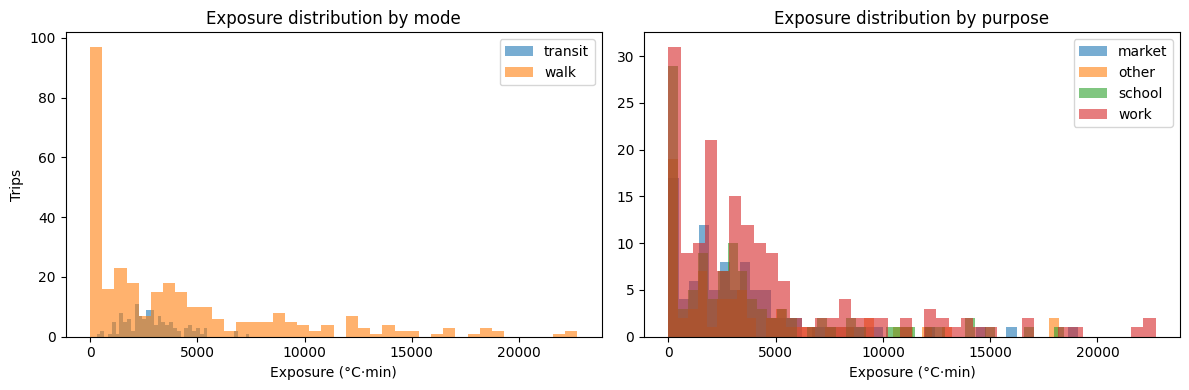

In [16]:
if not df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for mode, grp in df.groupby("mode_label"):
        axes[0].hist(grp["heat_degC_min"], bins=40, alpha=0.6, label=mode)
    axes[0].set_xlabel("Exposure (°C·min)")
    axes[0].set_ylabel("Trips")
    axes[0].set_title("Exposure distribution by mode")
    axes[0].legend()

    for purp, grp in df.groupby("purpose_label"):
        axes[1].hist(grp["heat_degC_min"], bins=40, alpha=0.6, label=purp)
    axes[1].set_xlabel("Exposure (°C·min)")
    axes[1].set_title("Exposure distribution by purpose")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### 3.2  Summary statistics

In [17]:
exp = result.agent_exposure_degC_min
active_mask = exp > 0  # agents that completed at least part of a trip

print(f"Agents with non-zero exposure : {active_mask.sum():,} / {len(exp):,}")
if active_mask.any():
    e = exp[active_mask]
    print(f"  Mean exposure : {e.mean():.1f} °C·min")
    print(f"  Median        : {np.median(e):.1f} °C·min")
    print(f"  90th pct      : {np.percentile(e, 90):.1f} °C·min")
    print(f"  Max           : {e.max():.1f} °C·min")

Agents with non-zero exposure : 418 / 500
  Mean exposure : 4893.4 °C·min
  Median        : 3640.5 °C·min
  90th pct      : 10729.2 °C·min
  Max           : 24075.5 °C·min


In [18]:
# Non-travel rate by purpose/age/gender — validates the travel_probability gating from
# §2.1c. NOTE: `active_mask` (above) is also False for agents where routing simply found
# no path (see the "No path for agent ..." warnings in §2.2), so this conflates "gated
# out by travel_probability" with "routing failure" — both mean zero exposure/zero trips,
# but they're not the same mechanism.
AGE_LABELS = {0: "child", 1: "youth", 2: "adult", 3: "elderly"}
GENDER_LABELS = {0: "male", 1: "female"}

breakdown = pd.DataFrame({
    "purpose": pd.Series(result.agent_purposes).map(PURP_LABELS),
    "age_group": pd.Series(result.agent_age_group).map(AGE_LABELS),
    "gender": pd.Series(result.agent_gender).map(GENDER_LABELS),
    "travelled": active_mask,
})

print("Non-travel rate by purpose:")
print((1 - breakdown.groupby("purpose")["travelled"].mean()).map("{:.0%}".format))
print("\nNon-travel rate by age group:")
print((1 - breakdown.groupby("age_group")["travelled"].mean()).map("{:.0%}".format))
print("\nNon-travel rate by gender:")
print((1 - breakdown.groupby("gender")["travelled"].mean()).map("{:.0%}".format))

Non-travel rate by purpose:
purpose
market    14%
other     22%
school    24%
work      11%
Name: travelled, dtype: object

Non-travel rate by age group:
age_group
adult      18%
child      15%
elderly    12%
youth      11%
Name: travelled, dtype: object

Non-travel rate by gender:
gender
female    18%
male      15%
Name: travelled, dtype: object


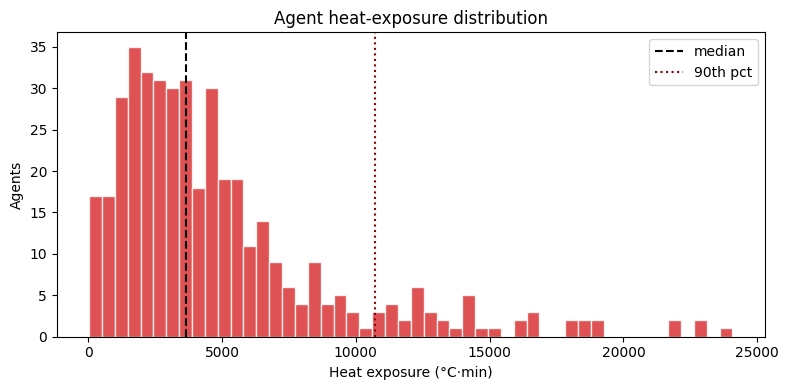

In [19]:
if active_mask.any():
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(exp[active_mask], bins=50, color="tab:red", alpha=0.8, edgecolor="white")
    ax.axvline(np.median(exp[active_mask]), color="k", linestyle="--", label="median")
    ax.axvline(np.percentile(exp[active_mask], 90), color="darkred", linestyle=":", label="90th pct")
    ax.set_xlabel("Heat exposure (°C·min)")
    ax.set_ylabel("Agents")
    ax.set_title("Agent heat-exposure distribution")
    ax.legend()
    plt.tight_layout()
    plt.show()

### 3.3  Spatial heatmap of exposure

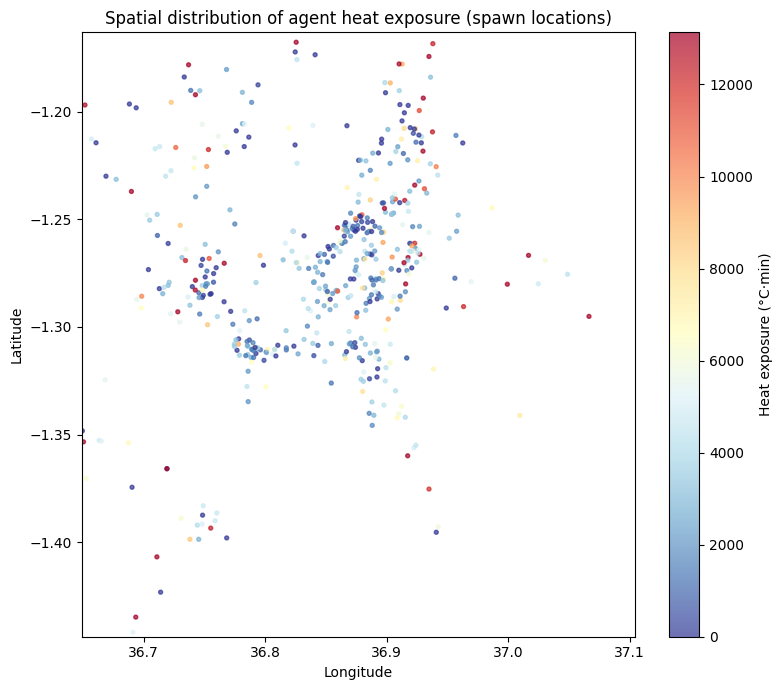

In [20]:
# Colour spawn nodes by the exposure accumulated during the run
# (uses the original spawn_nodes sample — only a proxy for actual agent positions)
rng2 = np.random.default_rng(42)
spawn_nodes_full, _, _ = sample_spawn_nodes(density, pop_transform, G, n_agents=N_AGENTS, rng=rng2)
node_xs_full = np.array([G.nodes[n]["x"] for n in spawn_nodes_full])
node_ys_full = np.array([G.nodes[n]["y"] for n in spawn_nodes_full])

south, west, north, east = BBOX
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(
    node_xs_full, node_ys_full,
    c=exp, cmap="RdYlBu_r", s=8, alpha=0.7,
    vmin=0, vmax=np.percentile(exp, 95),
)
plt.colorbar(sc, ax=ax, label="Heat exposure (°C·min)")
ax.set_xlim(west, east); ax.set_ylim(south, north)
ax.set_title("Spatial distribution of agent heat exposure (spawn locations)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

### 3.4  Where people spend the most time

The §3.3 heatmap above colours *spawn* locations by total exposure — a proxy for where agents live, not where they actually travel. This one is different: `result.time_density` (`model/scheduler.py::tick()`) accumulates person-minutes directly from each active agent's real interpolated position on the network, every tick of the run — the same lon/lat used to sample heat, binned into a grid (`SimulationParams.time_density_grid_shape`, default 200×200) via `data/population.py::lonlat_to_rowcol()`. So a cell's value answers "how many person-minutes were spent here," whether that's many agents passing through briefly (a busy corridor) or fewer agents lingering (e.g. waiting at a matatu stop, which counts too — `MODE_WAIT` agents are still active and still occupy a position).

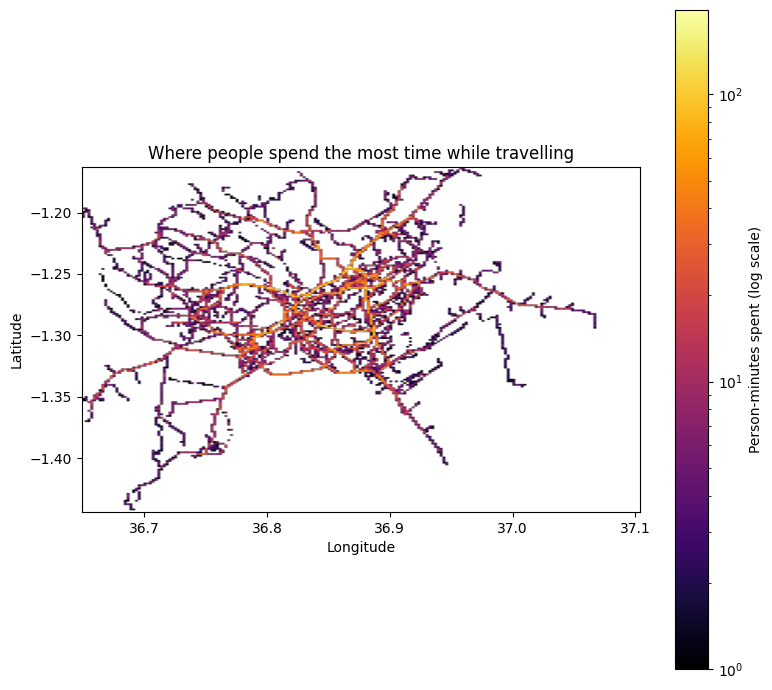

Grid: 200x200 cells, 62,781 total person-minutes tracked
Hottest cell: 196 person-minutes, near (36.8117, -1.2649)


In [21]:
from matplotlib.colors import LogNorm

grid = result.time_density
south, west, north, east = BBOX

if grid.sum() > 0:
    masked = np.ma.masked_where(grid <= 0, grid)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(
        masked, extent=[west, east, south, north],
        origin="upper", cmap="inferno", norm=LogNorm(vmin=masked.min(), vmax=masked.max()),
    )
    plt.colorbar(im, ax=ax, label="Person-minutes spent (log scale)")
    ax.set_xlim(west, east); ax.set_ylim(south, north)
    ax.set_title("Where people spend the most time while travelling")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    plt.tight_layout()
    plt.show()

    top_row, top_col = np.unravel_index(np.argmax(grid), grid.shape)
    top_lon, top_lat = rasterio.transform.xy(result.time_density_transform, top_row, top_col)
    print(f"Grid: {grid.shape[0]}x{grid.shape[1]} cells, {grid.sum():,.0f} total person-minutes tracked")
    print(f"Hottest cell: {grid[top_row, top_col]:,.0f} person-minutes, near ({top_lon:.4f}, {top_lat:.4f})")
else:
    print("time_density is all zero — no agents were ever active (check N_AGENTS/routing above).")

---
## Next steps

| Step | What to do |
|------|------------|
| Real population | Download 100 m WorldPop Kenya grids and save to `data/raw/nairobipop_{total,children,adult,elderly,female}.tif` |
| Real heat surface | Place multi-band GeoTIFF(s) in `data/raw/heat/` |
| Transit realism | Transfer-wait time isn't modeled (only the first boarding's wait is charged); no fare/informal-stop barriers |
| Scale up | Set `N_AGENTS = cfg['simulation']['default_n_agents']` (5,000) |
| RDM sweep | See Phase 4 plan — `rdm/sampling.py` + `rdm/batch.py` already scaffolded |
| Panel UI | Phase 3: wire `app/pages/*.py` view() methods once notebook validates the pipeline |